# 1. Why a variational principle

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Newton's laws, viscosity, partial derivatives

Soft matter moves slowly through viscous surroundings. A colloidal particle, a polymer
coil, a liquid film a few micrometres thick: none of them has inertia worth
mentioning, and their motion is decided at every instant by a balance between the
forces that drive them and the friction that resists. The usual way to describe such
motion is to write that balance down, force by force.

There is another way. The same equations follow from a single statement: *the rates
of change take the values that make a certain function, the Rayleighian, as small as
possible*. The Rayleighian is built from two scalars, the free energy of the system and
the rate at which its motion dissipates energy. This chapter shows, on the two
simplest examples, that the statement is true, what it means, and why it is worth
having: scalars are easier to write down than forces, and a minimum can be
approached by trial functions when the exact answer is out of reach.

Throughout the book each variational result is compared with an exact solution or
an accurate numerical solution of the same problem. Here the comparisons are with
the solution of the force-balance equation (Section 1.1) and with the exact series
for the flow in a square duct (Section 1.3).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 1.1 A particle in a viscous fluid

A small particle at position $x$ moves in a viscous fluid under a potential $U(x)$:
gravity, an optical trap, a spring. The fluid resists with a force $-\zeta\dot x$,
where $\zeta$ is the friction constant ($\zeta = 6\pi\eta a$ for a sphere of radius
$a$ in a fluid of viscosity $\eta$). Inertia is negligible, so the forces balance:

$$ -\zeta\dot x - \frac{dU}{dx} = 0 . \tag{1.1} $$

Now consider, at a given position $x$, the following function of the velocity
$\dot x$:

$$ R(\dot x; x) = \underbrace{\tfrac12\zeta\dot x^2}_{\Phi}
   \;+\; \underbrace{\frac{dU}{dx}\,\dot x}_{\dot A} . \tag{1.2} $$

It is a parabola in $\dot x$. Its minimum is where $\partial R/\partial\dot x = 0$,
that is, where $\zeta\dot x + dU/dx = 0$, which is Eq. (1.1). The force balance and
the statement "the velocity minimises $R$" are the same thing.

The two terms have names that will be used on every page of this book.

* $\Phi = \tfrac12\zeta\dot x^2$ is the **dissipation function**. The friction force
  does work at the rate $\zeta\dot x^2$, all of which becomes heat; $\Phi$ is half of
  that rate. The factor $\tfrac12$ is a convention that makes the derivative
  $\partial\Phi/\partial\dot x$ equal to the magnitude of the friction force, $\zeta\dot x$.
* $\dot A = (dU/dx)\,\dot x$ is the rate of change of the energy of the particle if
  it moves with velocity $\dot x$. In later chapters $U$ becomes a free energy $A$,
  whence the symbol.
* $R = \Phi + \dot A$ is the **Rayleighian**.

At the minimum $\zeta\dot x = -dU/dx$, so that

$$ \dot A = -\zeta\dot x^2 = -2\Phi \le 0 , \qquad R_{\min} = -\Phi . \tag{1.3} $$

The energy decreases, at exactly the rate at which friction turns it into heat.

Two remarks prevent misunderstandings later. First, $R$ is minimised with respect to
the *velocity*, with the position held fixed. It is a statement about the present
instant, not about a whole path, and it has to be applied again at the next instant.
Second, the particle does not minimise its dissipation: $\Phi$ alone is smallest at
$\dot x = 0$. It minimises the sum of the dissipation function and the rate of change
of the energy, and the compromise between "do not dissipate" and "lower the energy
quickly" is the actual velocity.

The cell below takes the statement literally. A particle moves in the double-well
potential $U = x^4/4 - x^2/2 - 0.2x$ (units with $\zeta = 1$). At each time step the
velocity is found by minimising $R$ numerically, with no reference to Eq. (1.1), and
the particle is moved by $\dot x\,\Delta t$. The result is compared with an accurate
solution of Eq. (1.1).

In [2]:
U = lambda x: x**4 / 4 - x**2 / 2 - 0.2 * x
dU = lambda x: x**3 - x - 0.2
zeta = 1.0


def rayleighian(v, x):
    return 0.5 * zeta * v**2 + dU(x) * v


def step_by_minimising(x0, t_end, dt):
    """Move the particle by repeatedly minimising R with respect to the velocity."""
    n = int(round(t_end / dt))
    x = np.empty(n + 1)
    x[0] = x0
    for i in range(n):
        v = minimize_scalar(rayleighian, args=(x[i],), bracket=(-1.0, 1.0), tol=1e-12).x
        x[i + 1] = x[i] + v * dt
    return np.linspace(0, t_end, n + 1), x


x0, t_end = -0.3, 12.0
reference = solve_ivp(lambda t, y: -dU(y) / zeta, (0, t_end), [x0], rtol=1e-11, atol=1e-13, dense_output=True)

steps = np.array([0.4, 0.2, 0.1, 0.05, 0.025])
err_step = []
for dt in steps:
    t, x = step_by_minimising(x0, t_end, dt)
    err_step.append(on.sup_error(x, reference.sol(t)[0]))
slope, _ = on.loglog_slope(steps, err_step)
print("time step    largest error")
for dt, e in zip(steps, err_step):
    print(f"  {dt:5.3f}       {e:.2e}")
print(f"slope on a log-log plot: {slope:.2f}  (1 expected: the stepping is of first order)")

t_demo, x_demo = step_by_minimising(x0, t_end, 0.1)

time step    largest error
  0.400       3.39e-02
  0.200       1.72e-02
  0.100       8.62e-03
  0.050       4.30e-03
  0.025       2.15e-03
slope on a log-log plot: 1.00  (1 expected: the stepping is of first order)


The particle slides down into the nearer, left-hand well, and the trajectory obtained by
minimisation converges to the solution of the force balance as the time step is
reduced, with the first-order accuracy of the simple stepping rule. Nothing in the
loop knows about forces.

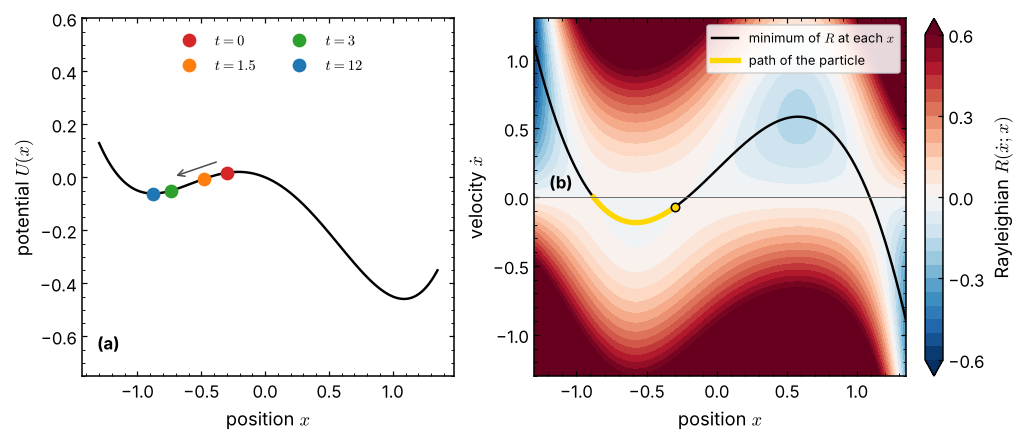

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

xs = np.linspace(-1.3, 1.35, 400)
ax1.plot(xs, U(xs), "k-")
for tm, c in zip((0.0, 1.5, 3.0, 12.0), ("C3", "C1", "C2", "C0")):
    xm = reference.sol(tm)[0]
    ax1.plot(xm, U(xm), "o", color=c, ms=8, label=f"$t = {tm:g}$")
ax1.annotate("", xy=(-0.72, U(-0.72) + 0.05), xytext=(-0.36, U(-0.36) + 0.05), arrowprops=dict(arrowstyle="->", color="0.3"))
ax1.set_xlabel("position $x$"); ax1.set_ylabel("potential $U(x)$"); ax1.set_ylim(-0.75, 0.6)
ax1.legend(loc="upper center", ncol=2); on.panel_label(ax1, "(a)", x=0.04, y=0.12)

XX, VV = np.meshgrid(xs, np.linspace(-1.3, 1.3, 300))
pcm = ax2.contourf(XX, VV, 0.5 * zeta * VV**2 + dU(XX) * VV, levels=np.linspace(-0.6, 0.6, 25), cmap="RdBu_r", extend="both")
ax2.plot(xs, -dU(xs) / zeta, "k-", lw=1.6, label=r"minimum of $R$ at each $x$")
xt = reference.sol(np.linspace(0, t_end, 300))[0]
ax2.plot(xt, -dU(xt) / zeta, "-", color="gold", lw=3.5, label="path of the particle")
ax2.plot(xt[0], -dU(xt[0]) / zeta, "o", color="gold", mec="k")
ax2.axhline(0, color="0.4", lw=0.6)
ax2.set_xlabel("position $x$"); ax2.set_ylabel(r"velocity $\dot x$")
fig.colorbar(pcm, ax=ax2, label=r"Rayleighian $R(\dot x; x)$", ticks=[-0.6, -0.3, 0, 0.3, 0.6])
ax2.legend(loc="upper right", fontsize=8.5, frameon=True, framealpha=0.85); on.panel_label(ax2, "(b)", x=0.04, y=0.57)
plt.show()

**Figure 1.1.** **(a)** The double-well potential and the position of the particle at
four times. **(b)** The Rayleighian as a function of position and velocity. At each
position (each vertical line) it is a parabola in the velocity; the black curve
joins the minima. The particle has no choice but to move along that curve: it
starts at the circle and comes to rest where the curve crosses zero velocity, which
is the bottom of the well. Negative values (blue) are velocities directed
downhill; the minimum is the best compromise between lowering the energy quickly
and dissipating little.

## 1.2 Why bother?

For one particle the Rayleighian is a roundabout way of writing one equation. Its
value appears when the system is less simple, for three reasons that the rest of
the book develops.

**Scalars are easier than forces.** To use Eq. (1.1) one must identify every force,
with its direction and its point of application. To use Eq. (1.2) one needs two
numbers: how much energy the system has in a given state, and how much it dissipates
when it moves in a given way. For a liquid film, a gel or a liquid crystal the two
scalars can be written in a line each, while the forces (pressures, stresses, torques)
take pages. Chapter 3 is a catalogue of the scalars.

**The structure is guaranteed.** Equations obtained by minimising a Rayleighian
always lower the free energy, and their friction coefficients are always symmetric.
These are the second law and Onsager's reciprocal relations (Chapter 2). A model
written down force by force can violate either by oversight; a model derived from
$A$ and $\Phi$ cannot.

**A minimum can be approximated.** If the exact motion makes $R$ as small as
possible, a motion restricted to a family of trial functions, chosen to make $R$ as
small as *it* can, is the best that family has to offer. This turns partial
differential equations into a few ordinary ones (Chapter 5), and it is the reason
the principle is a working tool and not only an elegant restatement. The next
section gives a first taste.

### When the principle applies

The statement "the rates minimise $\Phi + \dot A$" is not universal, and the book
stays within its range of validity:

* **Inertia is negligible.** Forces balance at every instant (low Reynolds number,
  overdamped motion). Oscillations and waves are outside the scope.
* **The temperature is uniform and constant**, so that the relevant thermodynamic
  potential is the free energy.
* **The system is close to local equilibrium**, so that the dissipation function is
  quadratic in the rates, that is, friction is linear in velocity. Yield-stress and
  strongly shear-thinning materials need a generalisation that is left for later.
* **The slow variables have been identified.** Everything else is assumed to relax
  quickly and to follow them.

Most of soft matter under ordinary conditions meets all four.

## 1.3 A field: flow in a duct

Let a viscous liquid flow along a straight duct of constant cross-section $S$, driven
by a pressure gradient $G = -dp/dz$. The velocity is along the duct and depends on
the position in the cross-section, $w(x, y)$, and it vanishes on the wall. The state
variable is now a field, and the Rayleighian is a functional of it.

*Dissipation function.* A viscous liquid sheared at the rate $|\nabla w|$ dissipates
energy at the rate $\eta|\nabla w|^2$ per unit volume. Per unit length of duct,

$$ \Phi[w] = \frac{\eta}{2}\int_S |\nabla w|^2\,dS . $$

*Energy.* The pressure difference does work on the liquid at the rate $G Q$ per unit
length, where $Q = \int_S w\,dS$ is the flow rate. This work is supplied by whatever
maintains the pressure (a raised reservoir, say), whose energy therefore falls:

$$ \dot A[w] = -G\int_S w\,dS . $$

*Rayleighian.*

$$ R[w] = \int_S \Big( \frac{\eta}{2}|\nabla w|^2 - G\,w \Big)\,dS . \tag{1.4} $$

To find the field that minimises it, change $w$ to $w + \delta w$, where $\delta w$ is
small and vanishes on the wall, and keep the terms of first order:

$$ \delta R = \int_S \big( \eta\,\nabla w\cdot\nabla\delta w - G\,\delta w \big)\,dS
            = -\int_S \big( \eta\nabla^2 w + G \big)\,\delta w\,dS . $$

The second form follows from integration by parts; the boundary term is zero
because $\delta w = 0$ on the wall. At the minimum $\delta R$ must vanish for every
$\delta w$, so

$$ \eta\nabla^2 w = -G , \tag{1.5} $$

which is the Stokes equation for this flow. Among all velocity fields that satisfy
the no-slip condition, the real one minimises the Rayleighian.

This is a form of a classical result. Helmholtz stated in 1868, and Korteweg proved
in 1883, that of all incompressible velocity fields with the same values on the
boundary, the solution of the Stokes equation dissipates the least energy. For a
duct the corresponding statement is that the real flow dissipates least among all
flows that carry the same flow rate $Q$. Minimising $\Phi$ at fixed $Q$ is the same
as minimising $\Phi - GQ$ with $G$ as a Lagrange multiplier (Chapter 3), which is
Eq. (1.4). The Onsager principle extends this theorem from viscous flow to
irreversible processes in general.

Multiplying Eq. (1.5) by $w$ and integrating gives $\eta\int|\nabla w|^2 dS = GQ$, so
at the minimum

$$ R_{\min} = -\tfrac12 G\,Q . \tag{1.6} $$

This has a useful consequence. Suppose Eq. (1.5) cannot be solved, as is the case
for most cross-sections. Take any family of trial fields that vanish on the wall,
$w = \sum_k a_k\phi_k(x, y)$, and choose the coefficients $a_k$ to minimise $R$. Because
$R$ is quadratic in the $a_k$, this is a set of linear equations,

$$ \sum_l K_{kl}\,a_l = \frac{G}{\eta}\,b_k , \qquad
   K_{kl} = \int_S \nabla\phi_k\cdot\nabla\phi_l\,dS , \quad b_k = \int_S \phi_k\,dS , $$

and the minimum over the family is again $-\tfrac12 G Q_{\rm trial}$, with
$Q_{\rm trial} = \sum_k a_k b_k$. Since the family cannot reach below the true minimum,

$$ Q_{\rm trial} \le Q . $$

A trial field always underestimates the flow rate, and each added trial function can
only raise the estimate towards the exact value.

The square duct, $-a < x, y < a$, is a good test, because its exact solution is known
as an infinite series (`on.duct_velocity`, `on.duct_flow_rate`). With lengths in units
of $a$ and velocities in units of $Ga^2/\eta$, take the trial functions

$$ \phi_{ij} = (1 - x^2)(1 - y^2)\,x^{2i}y^{2j} , \qquad i + j \le m . $$

The simplest choice, $m = 0$, is a single function, and the calculation can be done
by hand: $b = 16/9$, $K = 256/45$, $a_{00} = 5/16$, and $Q_{\rm trial} = 5/9 = 0.5556$,
against the exact $0.5623$.

In [4]:
nodes, weights = np.polynomial.legendre.leggauss(40)      # exact for the polynomials used here
X, Y = np.meshgrid(nodes, nodes)
W2 = np.outer(weights, weights)


def trial_functions(m):
    """phi_ij and their gradients on the quadrature grid, for i + j <= m."""
    out = []
    for i in range(m + 1):
        for j in range(m + 1 - i):
            px, py = X ** (2 * i), Y ** (2 * j)
            dpx = 2 * i * X ** (2 * i - 1) if i else 0 * X
            dpy = 2 * j * Y ** (2 * j - 1) if j else 0 * Y
            fx, fy = (1 - X**2) * px, (1 - Y**2) * py
            out.append((fx * fy, (-2 * X * px + (1 - X**2) * dpx) * fy, fx * (-2 * Y * py + (1 - Y**2) * dpy)))
    return out


def ritz(m):
    """Minimise the Rayleighian over the trial family; return a, Q and the field on the grid."""
    phi = trial_functions(m)
    K = np.array([[np.sum(W2 * (p[1] * q[1] + p[2] * q[2])) for q in phi] for p in phi])
    b = np.array([np.sum(W2 * p[0]) for p in phi])
    a = np.linalg.solve(K, b)
    return a, a @ b, sum(ak * p[0] for ak, p in zip(a, phi))


Q_exact = on.duct_flow_rate()
w_exact = on.duct_velocity(X, Y)
print(f"exact flow rate  Q = {Q_exact:.6f}  (units G a^4 / eta)\n")
print(" m   functions   Q_trial     error in Q    largest error in w")
n_funcs, err_Q, err_w = [], [], []
for m in range(5):
    a, Q, w = ritz(m)
    n_funcs.append(len(a)); err_Q.append(Q_exact - Q); err_w.append(on.sup_error(w, w_exact))
    print(f" {m}      {len(a):2d}       {Q:.6f}    {Q_exact - Q:9.2e}       {err_w[-1]:.2e}")
a0, Q0, w0 = ritz(0)
print(f"\none trial function: a = {a0[0]:.4f} (5/16 = {5/16:.4f}),  Q = {Q0:.4f} (5/9 = {5/9:.4f}),"
      f"  {100 * on.relative_error(Q0, Q_exact):+.1f} %")

exact flow rate  Q = 0.562308  (units G a^4 / eta)

 m   functions   Q_trial     error in Q    largest error in w
 0       1       0.555556     6.75e-03       1.76e-02
 1       3       0.561572     7.36e-04       4.61e-03
 2       6       0.562229     7.94e-05       1.45e-03
 3      10       0.562289     1.91e-05       6.79e-04
 4      15       0.562303     4.81e-06       3.30e-04

one trial function: a = 0.3125 (5/16 = 0.3125),  Q = 0.5556 (5/9 = 0.5556),  -1.2 %


One trial function gives the flow rate to 1.2 %; three give it to 0.13 %, and fifteen to
0.001 %. Every
estimate lies below the exact value and each is better than the last, as the
argument above requires.

The table also shows something that is typical of variational estimates. With one
trial function the velocity field is wrong by about 0.018 in places, which is 6 % of
its maximum, while the flow rate is wrong by only 1.2 %. The flow rate is, up to the
factor $-G/2$, the minimum value of $R$, and near a minimum a function changes only
to second order when its argument is displaced to first order. Quantities tied to the
value of the Rayleighian are therefore obtained more accurately than the field
itself. Chapter 5 returns to what can and cannot be trusted in a trial solution.

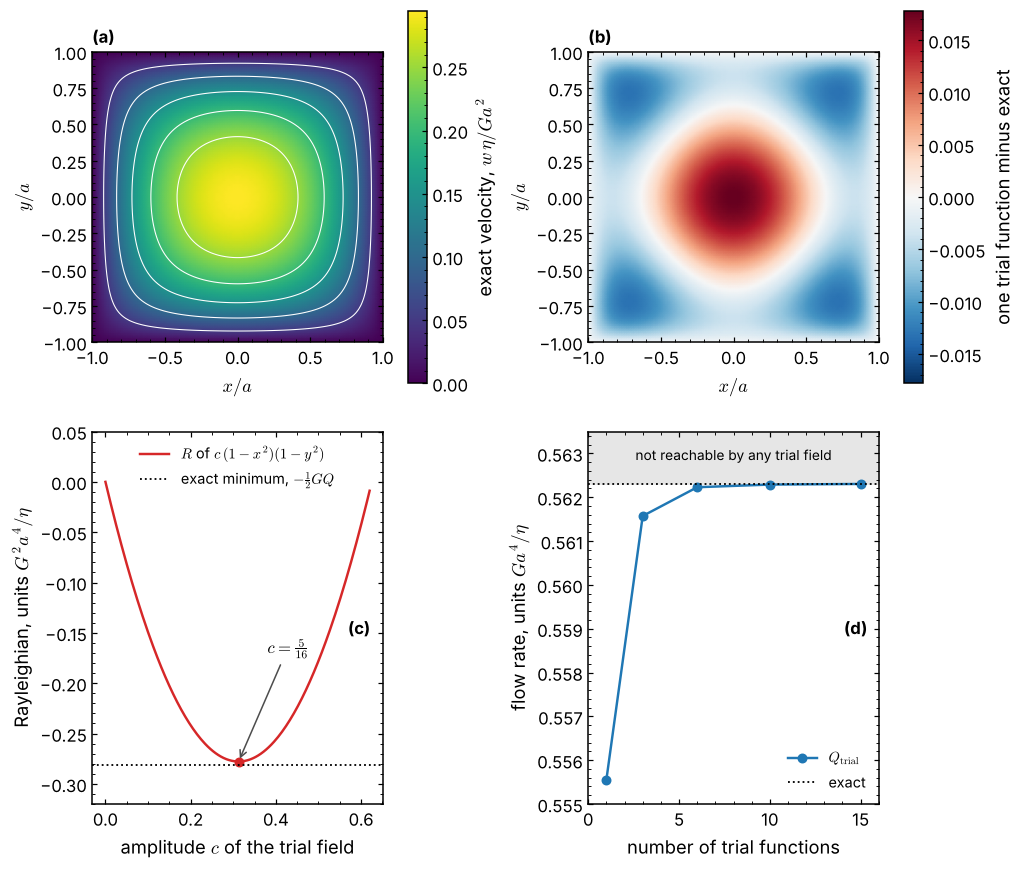

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.8))
gq = np.linspace(-1, 1, 121)
GXq, GYq = np.meshgrid(gq, gq)
w_ex_grid = on.duct_velocity(GXq, GYq)
w_one_grid = a0[0] * (1 - GXq**2) * (1 - GYq**2)

ax = axes[0, 0]
pcm = ax.pcolormesh(GXq, GYq, w_ex_grid, cmap="viridis", shading="gouraud")
ax.contour(GXq, GYq, w_ex_grid, levels=np.linspace(0.05, 0.25, 5), colors="w", linewidths=0.7)
ax.set_aspect("equal"); ax.set_xlabel("$x/a$"); ax.set_ylabel("$y/a$")
fig.colorbar(pcm, ax=ax, label=r"exact velocity, $w\,\eta/Ga^2$"); ax.set_title("(a)", loc="left", fontweight="bold")

ax = axes[0, 1]
lim = np.max(np.abs(w_one_grid - w_ex_grid))
pcm = ax.pcolormesh(GXq, GYq, w_one_grid - w_ex_grid, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="gouraud")
ax.set_aspect("equal"); ax.set_xlabel("$x/a$"); ax.set_ylabel("$y/a$")
fig.colorbar(pcm, ax=ax, label="one trial function minus exact"); ax.set_title("(b)", loc="left", fontweight="bold")

ax = axes[1, 0]
amp = np.linspace(0, 0.62, 200)
K1, b1 = 256 / 45, 16 / 9
ax.plot(amp, 0.5 * K1 * amp**2 - b1 * amp, color="C3", label=r"$R$ of $c\,(1-x^2)(1-y^2)$")
ax.plot(5 / 16, -5 / 18, "o", color="C3")
ax.axhline(-Q_exact / 2, color="k", ls=":", lw=1.2, label=r"exact minimum, $-\frac{1}{2}GQ$")
ax.annotate(r"$c = \frac{5}{16}$", xy=(5 / 16, -5 / 18), xytext=(0.38, -0.17), arrowprops=dict(arrowstyle="->", color="0.3"))
ax.set_xlabel("amplitude $c$ of the trial field"); ax.set_ylabel(r"Rayleighian, units $G^2a^4/\eta$")
ax.set_ylim(-0.32, 0.05); ax.legend(loc="upper center"); on.panel_label(ax, "(c)", x=0.88, y=0.5)

ax = axes[1, 1]
Q_values = [Q_exact - e for e in err_Q]
ax.plot(n_funcs, Q_values, "o-", color="C0", label=r"$Q_{\rm trial}$")
ax.axhline(Q_exact, color="k", ls=":", lw=1.2, label="exact")
ax.fill_between([0, 16], Q_exact, 0.5635, color="0.9")
ax.text(8, 0.56285, "not reachable by any trial field", ha="center", fontsize=9)
ax.set_xlim(0, 16); ax.set_ylim(0.555, 0.5635)
ax.set_xlabel("number of trial functions"); ax.set_ylabel(r"flow rate, units $Ga^4/\eta$")
ax.legend(loc="lower right"); on.panel_label(ax, "(d)", x=0.88, y=0.5)
plt.show()

**Figure 1.2.** **(a)** Exact velocity in the square duct. **(b)** Error of the single
trial function: too fast in the middle (red), too slow towards the corners and
walls (blue), since a product of two parabolas is more peaked than the real
profile. **(c)** The Rayleighian of the one-function trial field as its amplitude is
varied. Its lowest point lies just above the exact minimum, $-\tfrac12GQ$. **(d)** The
flow rate approaches the exact value from below as trial functions are added.

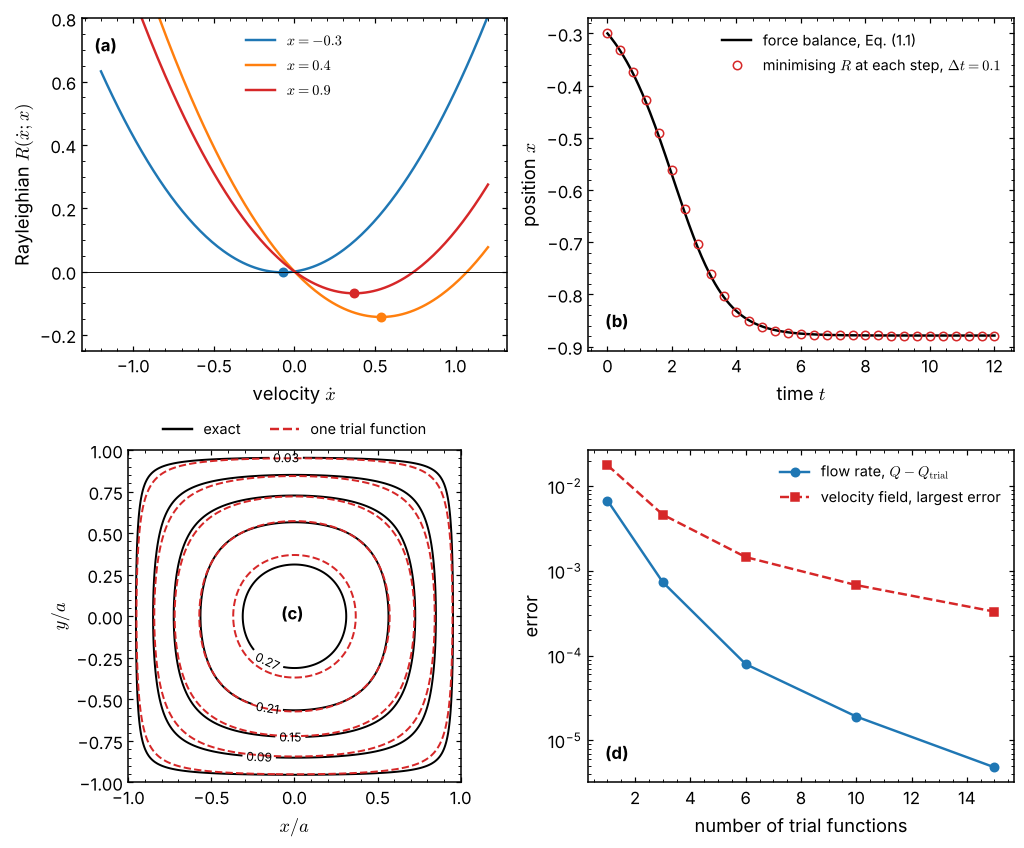

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
v = np.linspace(-1.2, 1.2, 200)
for xp, c in ((-0.3, "C0"), (0.4, "C1"), (0.9, "C3")):
    ax.plot(v, rayleighian(v, xp), color=c, label=f"$x = {xp}$")
    vmin = -dU(xp) / zeta
    ax.plot(vmin, rayleighian(vmin, xp), "o", color=c)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel(r"velocity $\dot x$"); ax.set_ylabel(r"Rayleighian $R(\dot x; x)$")
ax.set_ylim(-0.25, 0.8); ax.legend(loc="upper center"); on.panel_label(ax, "(a)")

ax = axes[0, 1]
tt = np.linspace(0, t_end, 400)
ax.plot(tt, reference.sol(tt)[0], "k-", label="force balance, Eq. (1.1)")
ax.plot(t_demo[::4], x_demo[::4], "o", color="C3", mfc="none", label=r"minimising $R$ at each step, $\Delta t = 0.1$")
ax.set_xlabel("time $t$"); ax.set_ylabel("position $x$")
ax.legend(loc="upper right"); on.panel_label(ax, "(b)", x=0.04, y=0.12)

ax = axes[1, 0]
g = np.linspace(-1, 1, 161)
GX, GY = np.meshgrid(g, g)
levels = np.linspace(0.03, 0.27, 5)
cs = ax.contour(GX, GY, on.duct_velocity(GX, GY), levels=levels, colors="k", linewidths=1.3)
ax.contour(GX, GY, a0[0] * (1 - GX**2) * (1 - GY**2), levels=levels, colors="C3", linewidths=1.3, linestyles="--")
ax.clabel(cs, fmt="%.2f", fontsize=8)
ax.plot([], [], "k-", label="exact"); ax.plot([], [], "--", color="C3", label="one trial function")
ax.set_aspect("equal"); ax.set_xlabel("$x/a$"); ax.set_ylabel("$y/a$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=2); on.panel_label(ax, "(c)", x=0.46, y=0.54)

ax = axes[1, 1]
ax.semilogy(n_funcs, err_Q, "o-", color="C0", label=r"flow rate, $Q - Q_{\rm trial}$")
ax.semilogy(n_funcs, err_w, "s--", color="C3", label="velocity field, largest error")
ax.set_xlabel("number of trial functions"); ax.set_ylabel("error")
ax.legend(loc="upper right"); on.panel_label(ax, "(d)", x=0.04, y=0.12)
plt.show()

**Figure 1.3.** **(a)** The Rayleighian of the particle of Section 1.1 as a function of velocity, at
three positions. Each curve is a parabola through the origin; the circle marks its
minimum, which is the velocity the particle takes at that position. **(b)** The
trajectory obtained by minimising $R$ at each time step, compared with the solution
of the force balance. **(c)** Velocity in a square duct, in units of $Ga^2/\eta$:
exact solution and the single trial function $\tfrac{5}{16}(1 - x^2)(1 - y^2)$.
**(d)** Errors of the trial solutions. The flow rate, which is tied to the minimum
value of $R$, is more accurate than the velocity field at every order.

## Summary

* For slow motion in a viscous medium, the rates of change minimise the Rayleighian
  $R = \Phi + \dot A$: the dissipation function plus the rate of change of the
  (free) energy. For a single particle this is the force balance, rewritten.
* The minimisation is over rates, at the present state. At the minimum
  $\dot A = -2\Phi$: the energy falls at the rate at which it is dissipated.
* The same statement holds for fields. For flow in a duct it gives the Stokes
  equation, and it is then a form of the minimum-dissipation theorem of slow viscous flow.
* A minimum can be approached with trial functions. One trial function gives the
  flow rate in a square duct to 1.2 %, always from below, and quantities tied to the
  value of $R$ are more accurate than the field.

## Exercises

Sample solutions are in [`solutions/part1_principle/01_solutions.ipynb`](../../solutions/part1_principle/01_solutions.ipynb).

1. **A sphere sedimenting in a trap.** A particle of weight $W$ is held by a spring,
   $U = Wx + \tfrac12kx^2$ with $x$ measured upwards. Write the Rayleighian, find
   $x(t)$ for a particle released at $x = 0$, and verify that the total heat dissipated,
   $\int_0^\infty 2\Phi\,dt$, equals the energy lost, $W^2/2k$.
2. **A circular tube.** For a tube of radius $a$ take the one-parameter trial field
   $w = c\,(1 - r^2/a^2)$. Show that minimising Eq. (1.4) gives $c = Ga^2/4\eta$ and
   $Q = \pi Ga^4/8\eta$. Why is the result exact?
3. **A rectangular duct.** For $-a < x < a$, $-ba < y < ba$, use the single trial
   function $(1 - x^2/a^2)(1 - y^2/b^2a^2)$ and show that
   $Q_{\rm trial} = \dfrac{10}{9}\,\dfrac{b^3}{b^2 + 1}\,\dfrac{Ga^4}{\eta}$. Compare with
   `on.duct_flow_rate(b)` for $b = 1, 2, 4$. (*Answer:* $-1.2$ %, $-2.8$ %, $-6.9$ %.)
   Why does a single trial function become worse as the duct becomes flatter, and
   what trial function would you use instead?
4. **Not a minimum of dissipation.** For the duct, show that the real flow
   *maximises* the flow rate among all trial fields scaled to dissipate at the rate
   they are supplied with energy ($\eta\int|\nabla w|^2 dS = GQ$).

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* H. Lamb, *Hydrodynamics*, 6th ed. (Cambridge University Press, 1932).
* G. K. Batchelor, *An Introduction to Fluid Dynamics* (Cambridge University Press, 1967).
* J. Happel and H. Brenner, *Low Reynolds Number Hydrodynamics* (Prentice-Hall, 1965; Martinus Nijhoff, 1983).
* M. Doi, "Onsager's variational principle in soft matter", *J. Phys.: Condens. Matter* **23**, 284118 (2011).
* D. J. Korteweg, "On a general theorem of the stability of the motion of a viscous fluid", *Phil. Mag.* **16**, 112 (1883).

---

**Next:** [2. Onsager's kinetic equations](02_kinetic_equations.ipynb)